# Bayesian Inference: CTCV J2056-3014
### *To view plots, visit [nbviewer](https://nbviewer.org/github/ericymiao/ctcvj2056-timing-spin-evolution/blob/main/mpl_notebooks/07_bayesian_inference.ipynb)*

We use the measured spin period derivative ($\dot{P}$) to constrain the white dwarf parameters under two accretion models:

1. **nmCV**: Non-magnetic CV with disk extending to WD surface. Parameters: $M_{\rm WD}$, $\dot{M}$.
2. **IP**: Intermediate Polar with piecewise disk–magnetosphere torque (Bhattacharyya & Chakrabarty 2017). Parameters: $M_{\rm WD}$, $\dot{M}$, $\mu$.

We perform nested sampling with `dynesty` to obtain posteriors and compute Bayes factors for model comparison.

In [3]:
import numpy as np
from scipy.interpolate import interp1d
from scipy.stats import norm
import matplotlib.pyplot as plt
import corner
import dynesty
from dynesty import utils as dyfunc
from dynesty import plotting as dyplot

plt.rcParams.update({
    'font.size': 13,
    'axes.labelsize': 13,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'figure.constrained_layout.use': True,
})

savedir = '../paper_figures'

## Constants, Data, and WD Mass-Radius-Inertia Relation

In [4]:
# --- Physical constants (CGS) ---
G = 6.674e-8       # cm^3 g^-1 s^-2
Msun = 1.989e33    # g
Rsun = 6.957e10    # cm

# --- Measured data (1-sigma) ---
P = 29.609685843       # spin period [s]
Pdot_obs = 0.0         # observed Pdot [s/s]
sigma_Pdot = 1.7e-15   # 1-sigma uncertainty on Pdot [s/s]

# --- Load WD mass-radius-inertia table ---
mr_data = np.loadtxt('../wd_mass_radius/mass_radius.txt', delimiter=',', skiprows=1)
M_table = mr_data[:, 0]   # M_sun
R_table = mr_data[:, 1]   # R_sun
I_table = mr_data[:, 2]   # g cm^2

# Interpolators: input in solar masses, output in CGS
get_R = interp1d(M_table, R_table * Rsun, kind='cubic')   # returns cm
get_I = interp1d(M_table, I_table, kind='cubic')           # returns g cm^2

M_min_table = M_table.min()
M_max_table = M_table.max()

xi = 0.5  # magnetospheric radius prefactor (r_m = xi * r_Alfven)

print(f"Table range: {M_min_table:.3f} - {M_max_table:.3f} Msun")
print(f"R(0.8 Msun) = {get_R(0.8)/1e8:.2f} x 10^8 cm")
print(f"I(0.8 Msun) = {get_I(0.8):.3e} g cm^2")

Table range: 0.010 - 1.406 Msun
R(0.8 Msun) = 6.66 x 10^8 cm
I(0.8 Msun) = 1.919e+50 g cm^2


## Forward Models

From $\Omega = 2\pi / P$ and $\dot{\Omega} = \tau / I$:

$$\dot{P}_{\rm pred} = -\frac{P^2}{2\pi I} \tau$$

**nmCV**: $r_{\rm in} = R_{\rm WD}$ (disk reaches surface). Torque $\tau = \dot{M}\sqrt{G M R_{\rm WD}}$.

**IP**: Piecewise torque from the disk–magnetosphere interaction (Bhattacharyya & Chakrabarty 2017, Eqs 9–10). The torque has two components: $N = N_{\rm acc} + N_{\rm field}$, with the regime determined by $r_m$ vs $r_{\rm co}$.

*Accretion phase* ($r_m \leq r_{\rm co}$):

$$\tau = \dot{M}\sqrt{G M r_m} + \frac{\mu^2}{9\,r_m^3}\left[2\left(\frac{r_m}{r_{\rm co}}\right)^3 - 6\left(\frac{r_m}{r_{\rm co}}\right)^{3/2} + 3\right]$$

*Propeller phase* ($r_m > r_{\rm co}$):

$$\tau = -\eta\,\dot{M}\sqrt{G M r_m} - \frac{\mu^2}{9\,r_m^3}\left[3 - 2\left(\frac{r_{\rm co}}{r_m}\right)^{3/2}\right]$$

where $\eta = 1$, $r_m = \xi \left(\frac{\mu^4}{2 G M \dot{M}^2}\right)^{1/7}$ with $\xi = 0.5$, and $r_{\rm co} = \left(\frac{G M P^2}{4\pi^2}\right)^{1/3}$.

The $N_{\rm field}$ term arises from integrating the magnetic stress $B_z B_\phi$ over the disk. In the accretion phase, the integral splits at $r_{\rm co}$: field lines inside $r_{\rm co}$ spin up the star, while those outside $r_{\rm co}$ brake it. In the propeller phase, $\Omega_K < \Omega$ everywhere in the disk, so the field always brakes. Both expressions are continuous at $r_m = r_{\rm co}$. Physical constraint: $r_m > R_{\rm WD}$.

Surface dipole field: $B = \mu / R^3$ (CGS).

In [5]:
def pdot_nmcv(M_wd_solar, log10_Mdot):
    """Predicted Pdot for the nmCV case (disk to surface)."""
    M = M_wd_solar * Msun
    Mdot = 10**log10_Mdot
    R = get_R(M_wd_solar)
    I = get_I(M_wd_solar)
    
    tau = Mdot * np.sqrt(G * M * R)
    return -P**2 * tau / (2 * np.pi * I)


def pdot_ip(M_wd_solar, log10_Mdot, log10_mu):
    """Predicted Pdot for IP case (piecewise disk-magnetosphere torque).
    
    Accretion phase (r_m <= r_co): Eq 9 of Bhattacharyya & Chakrabarty (2017).
    Propeller phase (r_m > r_co): Eq 10 (eta = 1).
    Returns NaN if r_m <= R_WD (unphysical).
    """
    M = M_wd_solar * Msun
    Mdot = 10**log10_Mdot
    mu = 10**log10_mu
    R = get_R(M_wd_solar)
    I = get_I(M_wd_solar)
    
    r_m = xi * (mu**4 / (2 * G * M * Mdot**2))**(1.0/7.0)
    r_co = (G * M * P**2 / (4 * np.pi**2))**(1.0/3.0)
    
    if r_m <= R:
        return np.nan
    
    if r_m <= r_co:
        # Accretion phase (Eq 9)
        x = r_m / r_co
        tau_acc = Mdot * np.sqrt(G * M * r_m)
        tau_mag = mu**2 / (9 * r_m**3) * (2 * x**3 - 6 * x**1.5 + 3)
    else:
        # Propeller phase (Eq 10, eta = 1)
        tau_acc = -Mdot * np.sqrt(G * M * r_m)
        tau_mag = -mu**2 / (9 * r_m**3) * (3 - 2 * (r_co / r_m)**1.5)
    
    return -P**2 * (tau_acc + tau_mag) / (2 * np.pi * I)


# --- Sanity checks ---
print(f"nmCV(0.935, 15): Pdot = {pdot_nmcv(0.935, 15):.3e}  (should be ~-2e-16)")
print(f"IP(0.815, 15, 30.3): Pdot = {pdot_ip(0.815, 15, 30.3):.3e}  (accretion phase)")
print(f"IP(0.815, 14, 33): Pdot = {pdot_ip(0.815, 14, 33):.3e}  (propeller phase, should be positive)")

nmCV(0.935, 15): Pdot = -2.381e-16  (should be ~-2e-16)
IP(0.815, 15, 30.3): Pdot = -3.262e-16  (accretion phase)
IP(0.815, 14, 33): Pdot = 1.216e-15  (propeller phase, should be positive)


## Priors and Likelihood

**Likelihood**: $\mathcal{L}(\dot{P}_{\rm obs} | \theta) = \mathcal{N}(\dot{P}_{\rm obs} \,|\, \dot{P}_{\rm pred}(\theta),\, \sigma_{\dot{P}})$

**Priors** (informed by Salcedo+2024 X-ray spectral fits):

| Parameter | nmCV | IP |
|-----------|------|-----|
| $M_{\rm WD}$ ($M_\odot$) | $\mathcal{N}(0.935, 0.058)$ | $\mathcal{N}(0.815, 0.055)$ |
| $\log_{10}\dot{M}$ (g/s) | $\mathcal{N}(15.5, 0.75)$ | $\mathcal{N}(15.5, 0.75)$ |
| $\log_{10}\mu$ (G cm³) | — | $\mathcal{U}(29, 34)$ |

nmCV mass prior from MKCFLOW fits (Table 6); IP mass prior from MCVSPEC fits (Table 7). The IP model allows $r_m > r_{\rm co}$ (propeller regime) — the only physical restriction is $r_m > R_{\rm WD}$.

In [6]:
# =====================================================
# nmCV model: 2 parameters [M_wd, log10_Mdot]
# =====================================================

NMCV_M_MU, NMCV_M_SIG = 0.935, 0.058
# LOGMDOT_LO, LOGMDOT_HI = 14, 17.0     # log10(Mdot) uniform (flat prior)
LOGMDOT_MU, LOGMDOT_SIG = 15.0, 0.5    # log10(Mdot) broad Gaussian


def prior_transform_nmcv(u):
    """Map unit cube [0,1]^2 -> nmCV parameter space."""
    theta = np.empty(2)
    theta[0] = norm.ppf(u[0], loc=NMCV_M_MU, scale=NMCV_M_SIG)
    theta[0] = np.clip(theta[0], M_min_table + 0.001, M_max_table - 0.001)
    theta[1] = norm.ppf(u[1], loc=LOGMDOT_MU, scale=LOGMDOT_SIG)
    return theta


def log_likelihood_nmcv(theta):
    """Log-likelihood for nmCV model."""
    M_wd, log_Mdot = theta
    if M_wd <= M_min_table or M_wd >= M_max_table:
        return -1e100
    
    Pdot_pred = pdot_nmcv(M_wd, log_Mdot)
    return -0.5 * ((Pdot_obs - Pdot_pred) / sigma_Pdot)**2


# =====================================================
# IP model: 3 parameters [M_wd, log10_Mdot, log10_mu]
# (piecewise torque — accretion + propeller regimes)
# =====================================================

IP_M_MU, IP_M_SIG = 0.815, 0.055        # Gaussian mass prior
LOGMU_LO, LOGMU_HI = 30.0, 34.0          # log10(mu) uniform


def prior_transform_ip(u):
    """Map unit cube [0,1]^3 -> IP parameter space."""
    theta = np.empty(3)
    theta[0] = norm.ppf(u[0], loc=IP_M_MU, scale=IP_M_SIG)
    theta[0] = np.clip(theta[0], M_min_table + 0.001, M_max_table - 0.001)
    theta[1] = norm.ppf(u[1], loc=LOGMDOT_MU, scale=LOGMDOT_SIG)
    theta[2] = LOGMU_LO + u[2] * (LOGMU_HI - LOGMU_LO)
    return theta


def log_likelihood_ip(theta):
    """Log-likelihood for IP model."""
    M_wd, log_Mdot, log_mu = theta
    if M_wd <= M_min_table or M_wd >= M_max_table:
        return -1e100
    
    Pdot_pred = pdot_ip(M_wd, log_Mdot, log_mu)
    if np.isnan(Pdot_pred):  # r_m < R_WD
        return -1e100
    
    return -0.5 * ((Pdot_obs - Pdot_pred) / sigma_Pdot)**2

## Nested Sampling

In [7]:
print("Running IP nested sampling (3 params, piecewise torque)...")
sampler_ip = dynesty.DynamicNestedSampler(
    log_likelihood_ip, prior_transform_ip, ndim=3,
    nlive=500, bound='multi', sample='rwalk'
)
sampler_ip.run_nested( print_progress=True)
results_ip = sampler_ip.results
print(f"IP done: logZ = {results_ip['logz'][-1]:.2f} +/- {results_ip['logzerr'][-1]:.2f}")

Running IP nested sampling (3 params, piecewise torque)...


13502it [00:12, 1073.70it/s, batch: 11 | bound: 0 | nc: 1 | ncall: 72963 | eff(%): 18.505 | loglstar:   -inf < -0.000 < -0.050 | logz: -1.101 +/-  0.021 | stop:  0.898]        

IP done: logZ = -1.11 +/- 0.02


In [8]:
print("Running nmCV nested sampling (2 params)...")
sampler_nmcv = dynesty.DynamicNestedSampler(
    log_likelihood_nmcv, prior_transform_nmcv, ndim=2,
    nlive=500, bound='multi', sample='rwalk'
)
sampler_nmcv.run_nested(print_progress=True)
results_nmcv = sampler_nmcv.results
print(f"nmCV done: logZ = {results_nmcv['logz'][-1]:.2f} +/- {results_nmcv['logzerr'][-1]:.2f}")

Running nmCV nested sampling (2 params)...


11512it [00:06, 1671.75it/s, batch: 12 | bound: 0 | nc: 1 | ncall: 39516 | eff(%): 29.121 | loglstar: -1.171 < -0.000 < -0.016 | logz: -0.064 +/-  0.004 | stop:  0.974]        

nmCV done: logZ = -0.06 +/- 0.00


## Results

In [9]:
# --- Extract equal-weight posterior samples ---

# IP
weights_ip = np.exp(results_ip['logwt'] - results_ip['logz'][-1])
weights_ip /= weights_ip.sum()
samples_ip_eq = dyfunc.resample_equal(results_ip['samples'], weights_ip)

# Derived: B = mu / R^3
R_samples_ip = np.array([get_R(m) for m in samples_ip_eq[:, 0]])
mu_samples_ip = 10**samples_ip_eq[:, 2]
B_samples_ip = mu_samples_ip / R_samples_ip**3
log10_B_samples_ip = np.log10(B_samples_ip)

# nmCV
weights_nmcv = np.exp(results_nmcv['logwt'] - results_nmcv['logz'][-1])
weights_nmcv /= weights_nmcv.sum()
samples_nmcv_eq = dyfunc.resample_equal(results_nmcv['samples'], weights_nmcv)


# --- Summary statistics ---
def summarize(samples, labels):
    for i, label in enumerate(labels):
        med = np.median(samples[:, i])
        lo, hi = np.percentile(samples[:, i], [16, 84])
        print(f'  {label}: {med:.4f}  (+{hi-med:.4f} / -{med-lo:.4f})')

print('=== IP posteriors ===')
summarize(samples_ip_eq, [r'M_WD [Msun]', r'log10(Mdot) [g/s]', r'log10(mu) [G cm^3]'])
med_B = np.median(log10_B_samples_ip)
lo_B, hi_B = np.percentile(log10_B_samples_ip, [16, 84])
print(f'  log10(B) [G]: {med_B:.2f}  (+{hi_B-med_B:.2f} / -{med_B-lo_B:.2f})')
print(f'  B [MG]: {10**med_B/1e6:.2f}')

print('\n=== nmCV posteriors ===')
summarize(samples_nmcv_eq, [r'M_WD [Msun]', r'log10(Mdot) [g/s]'])

=== IP posteriors ===
  M_WD [Msun]: 0.8120  (+0.0540 / -0.0550)
  log10(Mdot) [g/s]: 14.6810  (+0.4555 / -0.4608)
  log10(mu) [G cm^3]: 30.8485  (+1.1351 / -0.5352)
  log10(B) [G]: 4.41  (+1.11 / -0.54)
  B [MG]: 0.03

=== nmCV posteriors ===
  M_WD [Msun]: 0.9345  (+0.0576 / -0.0590)
  log10(Mdot) [g/s]: 14.9636  (+0.4537 / -0.4884)


**Interpretation**: The IP model achieves $\dot{P} \approx 0$ through torque cancellation near spin equilibrium ($r_m \approx r_{\rm co}$), allowing a wide range of $\dot{M}$ and $\mu$ values. In contrast, the nmCV model can only produce $\dot{P} \approx 0$ through a small accretion torque, requiring low $\dot{M}$. The IP posterior on $\log_{10}\dot{M}$ may therefore extend to higher values, with $\mu$ favoring values that place $r_m$ near corotation.

### Bayes Factor

In [10]:
logZ_ip = results_ip['logz'][-1]
logZ_ip_err = results_ip['logzerr'][-1]
logZ_nmcv = results_nmcv['logz'][-1]
logZ_nmcv_err = results_nmcv['logzerr'][-1]

print('=== Model Evidence ===')
print(f'  ln(Z_IP)   = {logZ_ip:.2f} +/- {logZ_ip_err:.2f}')
print(f'  ln(Z_nmCV) = {logZ_nmcv:.2f} +/- {logZ_nmcv_err:.2f}')
print()


def jeffreys_scale(abs_lnBF):
    if abs_lnBF < 1:
        return 'Not worth more than a bare mention'
    elif abs_lnBF < 2.5:
        return 'Substantial'
    elif abs_lnBF < 5:
        return 'Strong'
    else:
        return 'Decisive'


lnBF = logZ_ip - logZ_nmcv
lnBF_err = np.sqrt(logZ_ip_err**2 + logZ_nmcv_err**2)
BF = np.exp(lnBF)
strength = jeffreys_scale(abs(lnBF))
favored = 'IP' if lnBF > 0 else 'nmCV'

print('=== Bayes Factor ===')
print(f'{"Comparison":<16} {"ln(BF)":<16} {"BF":<12} {"Interpretation"}')
print('-' * 65)
print(f'{"IP/nmCV":<16} {lnBF:+.2f} +/- {lnBF_err:.2f}  {BF:<12.4f} {strength} ({favored})')

=== Model Evidence ===
  ln(Z_IP)   = -1.11 +/- 0.02
  ln(Z_nmCV) = -0.06 +/- 0.00

=== Bayes Factor ===
Comparison       ln(BF)           BF           Interpretation
-----------------------------------------------------------------
IP/nmCV          -1.05 +/- 0.02  0.3501       Substantial (nmCV)


**Interpretation**: The IP/nmCV Bayes factor tests whether the 3-parameter IP model with piecewise torque (accretion + propeller regimes, enabling torque cancellation near spin equilibrium) overcomes the Occam penalty relative to the simpler 2-parameter nmCV model. The nmCV model has a built-in advantage: with only 2 parameters, a larger fraction of its prior volume is consistent with $\dot{P} \approx 0$. The IP model must compensate through its richer physics — specifically, that torque cancellation near $r_m \approx r_{\rm co}$ naturally produces $\dot{P} \approx 0$ across a wider range of $\dot{M}$.

### Corner Plots

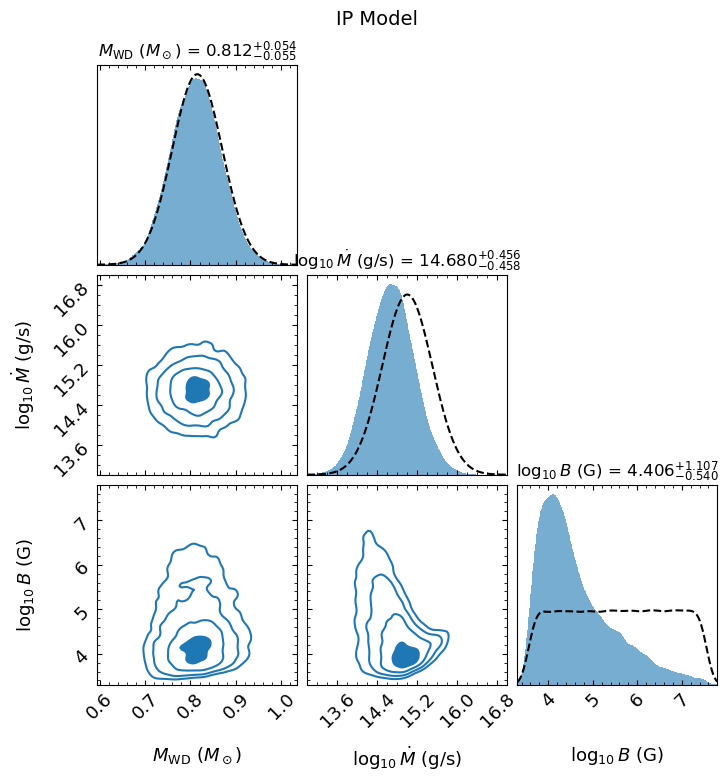

In [30]:
# --- IP corner plot (M_WD, log Mdot, log B) with prior overlays ---
import copy
from scipy.stats import gaussian_kde

# Create modified results with log10(B) replacing log10(mu)
results_ip_B = copy.deepcopy(results_ip)
R_arr = np.array([get_R(m) for m in results_ip_B['samples'][:, 0]])
B_arr = 10**results_ip_B['samples'][:, 2] / R_arr**3
results_ip_B['samples'][:, 2] = np.log10(B_arr)

# Compute B prior range for span
np.random.seed(42)
M_prior = np.random.normal(IP_M_MU, IP_M_SIG, 100000)
M_prior = np.clip(M_prior, M_min_table + 0.001, M_max_table - 0.001)
logmu_prior = np.random.uniform(LOGMU_LO, LOGMU_HI, 100000)
R_prior = np.array([get_R(m) for m in M_prior])
logB_prior = logmu_prior - 3 * np.log10(R_prior)

# Spans: include full prior range (±4σ for Gaussians, full range for B prior)
span_ip = [
    (IP_M_MU - 4*IP_M_SIG, IP_M_MU + 4*IP_M_SIG),
    (LOGMDOT_MU - 4*LOGMDOT_SIG, LOGMDOT_MU + 4*LOGMDOT_SIG),
    (np.min(logB_prior), np.max(logB_prior)),
]

plt.rcParams['figure.constrained_layout.use'] = False
fig, axes = dyplot.cornerplot(
    results_ip_B,
    span=span_ip,
    labels=[r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)', r'$\log_{10} B$ (G)'],
    quantiles=None,#[0.16, 0.5, 0.84],
    #quantiles_2d = [0.5, 1, 2],
    show_titles=True,
    title_quantiles=[0.16, 0.5, 0.84],
    title_fmt='.3f',
    title_kwargs={'fontsize': 12},
    label_kwargs={'fontsize': 13},
    color='C0',
)


def overlay_prior(ax, grid, pdf, **kwargs):
    """Scale prior PDF to match histogram area for correct normalization."""
    hist_area = sum(p.get_width() * p.get_height()
                    for p in ax.patches if p.get_height() > 0)
    if hist_area <= 0:
        return
    prior_area = np.trapezoid(pdf, grid)
    if prior_area <= 0:
        return
    pdf_scaled = pdf * (hist_area / prior_area)
    ax.plot(grid, pdf_scaled, **kwargs)
    # Expand ylim if prior extends above posterior
    ymax = max(ax.get_ylim()[1], pdf_scaled.max() * 1.05)
    ax.set_ylim([0, ymax])


# M_WD prior
ax = axes[0, 0]
M_grid = np.linspace(*span_ip[0], 300)
overlay_prior(ax, M_grid, norm.pdf(M_grid, IP_M_MU, IP_M_SIG),
              color='k', ls='--', lw=1.5, label='Prior')

# log10(Mdot) prior
ax = axes[1, 1]
Mdot_grid = np.linspace(*span_ip[1], 300)
overlay_prior(ax, Mdot_grid, norm.pdf(Mdot_grid, LOGMDOT_MU, LOGMDOT_SIG),
              color='k', ls='--', lw=1.5)

# log10(B) prior (derived — use KDE of prior samples)
ax = axes[2, 2]
kde_B = gaussian_kde(logB_prior)
B_grid = np.linspace(*span_ip[2], 300)
overlay_prior(ax, B_grid, kde_B(B_grid), color='k', ls='--', lw=1.5)

fig.suptitle('IP Model', fontsize=14, y=1.02)
fig.savefig(f'{savedir}/bayesian_corner_ip.pdf', bbox_inches='tight')
plt.show()
plt.rcParams['figure.constrained_layout.use'] = True


/opt/miniconda3/envs/CTCV_PINT/lib/python3.13/site-packages/dynesty/plotting.py:1306: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig.subplots_adjust(left=lb,
/var/folders/vt/3pcpgl9s1m9dr65kms8vmpth0000gn/T/ipykernel_67495/718509594.py:47: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  prior_area = np.trapz(pdf, grid)


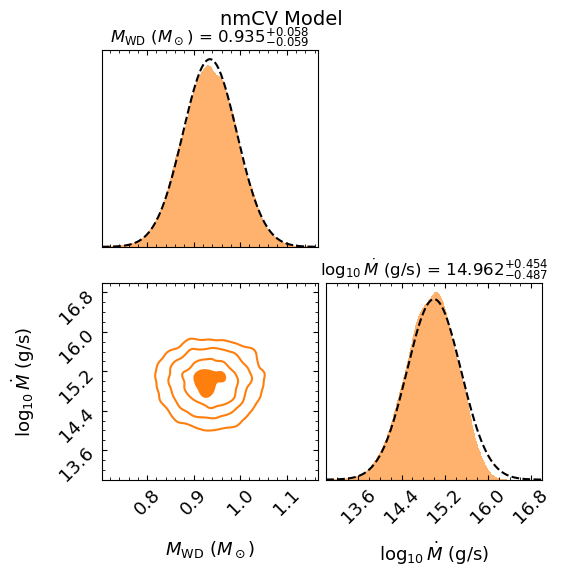

In [12]:
# --- nmCV corner plot (M_WD, log Mdot) with prior overlays ---
span_nmcv = [
    (NMCV_M_MU - 4*NMCV_M_SIG, NMCV_M_MU + 4*NMCV_M_SIG),
    (LOGMDOT_MU - 4*LOGMDOT_SIG, LOGMDOT_MU + 4*LOGMDOT_SIG),
]

plt.rcParams['figure.constrained_layout.use'] = False
fig, axes = dyplot.cornerplot(
    results_nmcv,
    span=span_nmcv,
    labels=[r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)'],
    quantiles=None,#[0.16, 0.5, 0.84],
    show_titles=True,
    title_quantiles=[0.16, 0.5, 0.84],
    title_fmt='.3f',
    title_kwargs={'fontsize': 12},
    label_kwargs={'fontsize': 13},
    color='C1',
)

# M_WD prior
ax = axes[0, 0]
M_grid = np.linspace(*span_nmcv[0], 300)
overlay_prior(ax, M_grid, norm.pdf(M_grid, NMCV_M_MU, NMCV_M_SIG),
              color='k', ls='--', lw=1.5, label='Prior')

# log10(Mdot) prior
ax = axes[1, 1]
Mdot_grid = np.linspace(*span_nmcv[1], 300)
overlay_prior(ax, Mdot_grid, norm.pdf(Mdot_grid, LOGMDOT_MU, LOGMDOT_SIG),
              color='k', ls='--', lw=1.5)

fig.suptitle('nmCV Model', fontsize=14, y=1.02)
fig.savefig(f'{savedir}/bayesian_corner_nmcv.pdf', bbox_inches='tight')
plt.show()
plt.rcParams['figure.constrained_layout.use'] = True


### Sampling Diagnostics

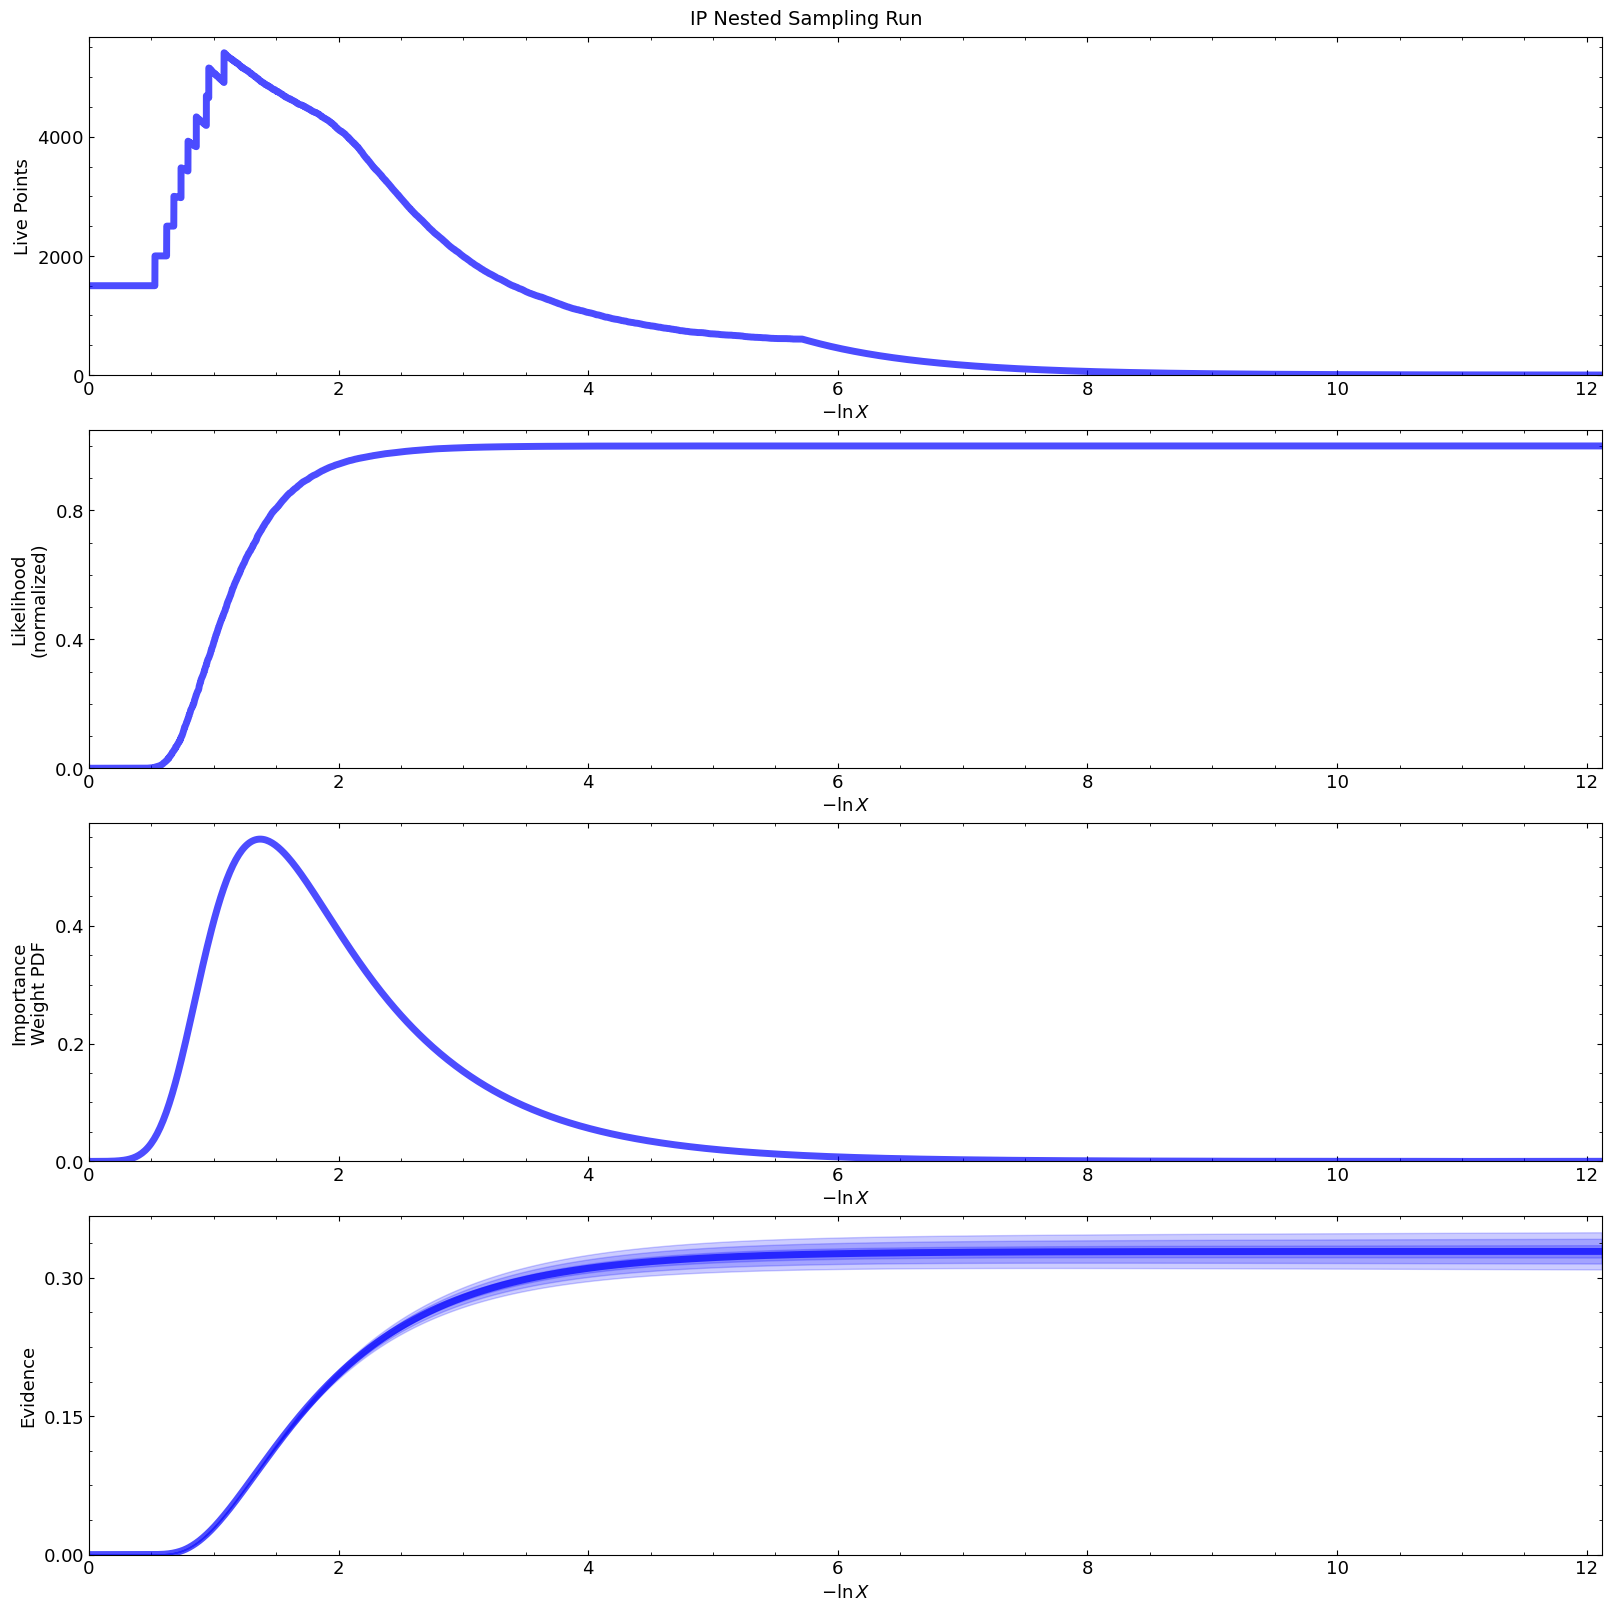

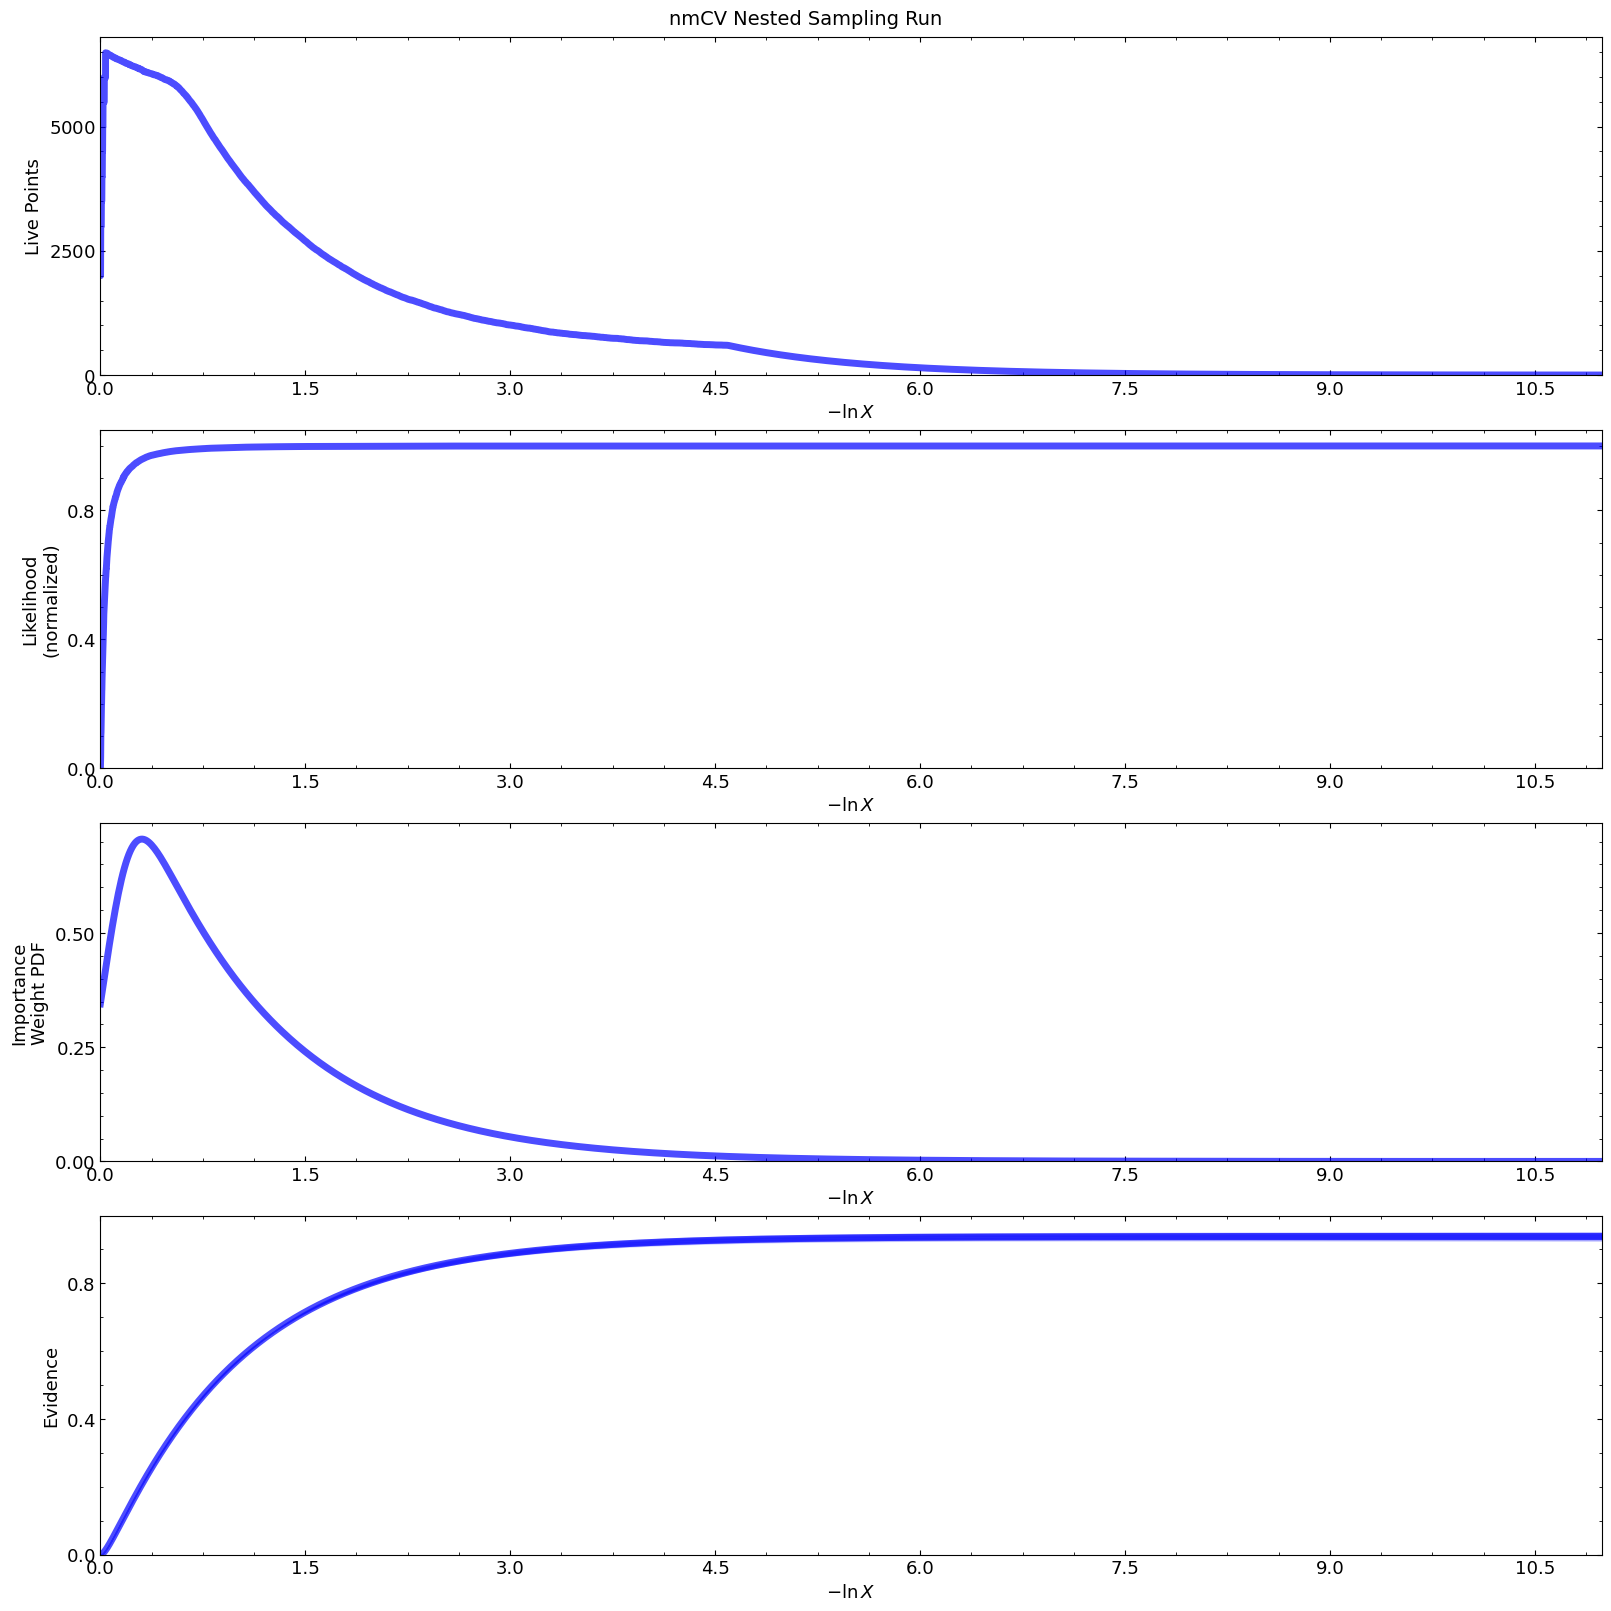

In [13]:
plt.rcParams['figure.constrained_layout.use'] = False
fig, axes = dyplot.runplot(results_ip)
fig.suptitle('IP Nested Sampling Run', fontsize=14)
fig.savefig(f'{savedir}/bayesian_runplot_ip.pdf', bbox_inches='tight')
plt.show()
plt.rcParams['figure.constrained_layout.use'] = True

plt.rcParams['figure.constrained_layout.use'] = False
fig, axes = dyplot.runplot(results_nmcv)
fig.suptitle('nmCV Nested Sampling Run', fontsize=14)
fig.savefig(f'{savedir}/bayesian_runplot_nmcv.pdf', bbox_inches='tight')
plt.show()
plt.rcParams['figure.constrained_layout.use'] = True


### Predicted $\dot{P}$ Distribution

nmCV:
  Pdot median = -2.20e-16 s/s
  |Pdot| < 3.64e-16 (68%), < 8.35e-16 (90%), < 1.13e-15 (95%)
IP:
  Pdot median = 6.32e-16 s/s
  |Pdot| < 1.23e-15 (68%), < 2.25e-15 (90%), < 2.74e-15 (95%)
  Fraction with Pdot > 0 (spin-down): 76.1%
  Fraction with |Pdot| < 1e-17 (near-exact equilibrium): 1.2%


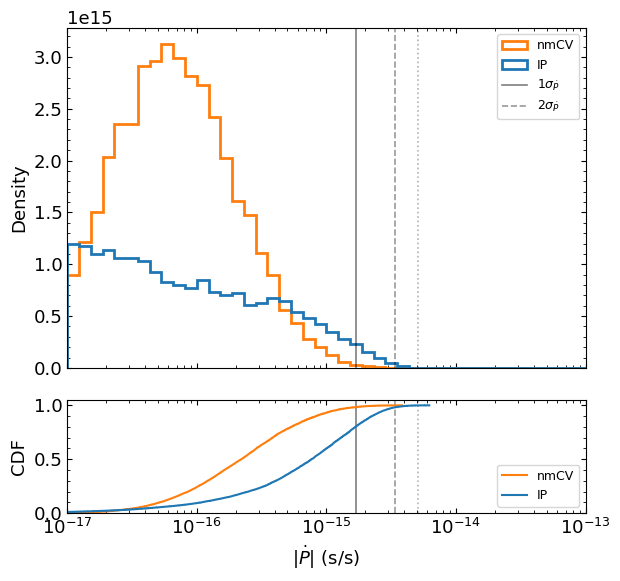

In [14]:
# Compute Pdot from posterior samples
Pdot_nmcv_samples = np.array([
    pdot_nmcv(s[0], s[1]) for s in samples_nmcv_eq
])
Pdot_ip_samples = np.array([
    pdot_ip(s[0], s[1], s[2]) for s in samples_ip_eq
])

# --- Posterior predictive Pdot constraints ---
valid_ip = Pdot_ip_samples[~np.isnan(Pdot_ip_samples)]

for label, samps in [('nmCV', Pdot_nmcv_samples), ('IP', valid_ip)]:
    abs_samps = np.abs(samps)
    med = np.median(samps)
    p68 = np.percentile(abs_samps, 68)
    p90 = np.percentile(abs_samps, 90)
    p95 = np.percentile(abs_samps, 95)
    print(f'{label}:')
    print(f'  Pdot median = {med:.2e} s/s')
    print(f'  |Pdot| < {p68:.2e} (68%), < {p90:.2e} (90%), < {p95:.2e} (95%)')
    if label == 'IP':
        frac_pos = np.sum(samps[~np.isnan(samps)] > 0) / len(valid_ip) * 100
        print(f'  Fraction with Pdot > 0 (spin-down): {frac_pos:.1f}%')
        frac_tiny = np.sum(abs_samps < 1e-17) / len(valid_ip) * 100
        print(f'  Fraction with |Pdot| < 1e-17 (near-exact equilibrium): {frac_tiny:.1f}%')

# --- Visualization ---
fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(6.4, 6),
                                      gridspec_kw={'height_ratios': [3, 1]},
                                      sharex=True, layout='tight')

abs_nmcv = np.abs(Pdot_nmcv_samples)
abs_ip = np.abs(valid_ip)

# Focus on the physically relevant range
bins = np.logspace(-17, -13, 45)

# Use histtype='step' so distributions don't obscure each other
ax_top.hist(abs_nmcv, bins=bins, density=True, histtype='step', lw=2, color='C1', label='nmCV')
ax_top.hist(abs_ip, bins=bins, density=True, histtype='step', lw=2, color='C0', label='IP')

for nsig, ls, alph in [(1, '-', 0.5), (2, '--', 0.4), (3, ':', 0.3)]:
    ax_top.axvline(nsig * sigma_Pdot, color='k', ls=ls, alpha=alph, lw=1.2,
                   label=f'${nsig}\\sigma_{{\\dot{{P}}}}$' if nsig <= 2 else None)
    ax_bot.axvline(nsig * sigma_Pdot, color='k', ls=ls, alpha=alph, lw=1.2)

ax_top.set_xscale('log')
ax_top.set_ylabel('Density')
ax_top.legend(fontsize=9)

# CDF
for samps, color, label in [(abs_nmcv, 'C1', 'nmCV'), (abs_ip, 'C0', 'IP')]:
    x_cdf = np.sort(samps)
    ax_bot.step(x_cdf, np.arange(1, len(x_cdf)+1) / len(x_cdf), color=color, lw=1.5, label=label)

ax_bot.set_xlabel(r'$|\dot{P}|$ (s/s)')
ax_bot.set_ylabel('CDF')
ax_bot.set_ylim(0, 1.05)
ax_bot.set_xlim(1e-17, 1e-13)
ax_bot.legend(fontsize=9, loc='lower right')

fig.savefig(f'{savedir}/bayesian_pdot_posterior.pdf', bbox_inches='tight')
plt.show()

**Interpretation**: The nmCV model predicts strictly negative $\dot{P}$ (spin-up from accretion). The IP model can produce *both* positive and negative $\dot{P}$: in the propeller regime ($r_m > r_{\rm co}$), material is ejected and the magnetic field brakes the star, yielding $\dot{P} > 0$. Near spin equilibrium ($r_m \approx r_{\rm co}$), the accretion and braking torques nearly cancel, naturally producing $\dot{P} \approx 0$. The fraction of IP posterior samples with $\dot{P} > 0$ indicates how close the system is to exact spin equilibrium.

## Summary

**Method**: Nested sampling (dynesty, $n_{\rm live} = 1000$) with $\dot{P} = 0.0 \pm 1.7 \times 10^{-15}$ s/s as the constraining measurement.

**Two models compared**:

1. **nmCV (non-magnetic)**: Torque $= \dot{M}\sqrt{GM R}$ (disk to surface, spin-up only). Achieves $\dot{P} \approx 0$ only through small $\dot{M}$. With only 2 free parameters, it benefits from Occam's razor.

2. **IP (Intermediate Polar)**: Piecewise torque from Bhattacharyya & Chakrabarty (2017). Accretion phase ($r_m \leq r_{\rm co}$): material accretion + magnetic field threading with split integral at $r_{\rm co}$. Propeller phase ($r_m > r_{\rm co}$): material ejection + magnetic braking. Achieves $\dot{P} \approx 0$ through *torque cancellation* near spin equilibrium ($r_m \approx r_{\rm co}$), allowing a wider range of $\dot{M}$ and $\mu$.

**Key results**:
- The **Bayes factor** quantifies whether the IP model's richer torque physics (3 parameters, piecewise torque with spin equilibrium) overcomes the Occam penalty relative to the simpler nmCV model (2 parameters).
- The IP model constrains $B = \mu/R^3$, with the posterior reflecting the spin-equilibrium condition $r_m \approx r_{\rm co}$.
- The IP model can produce both spin-up and spin-down, while nmCV predicts only spin-up.

## Prior Sensitivity Analysis

Re-run nested sampling under alternative prior assumptions to test whether the Bayes factor and posteriors are robust to prior choices. Mass priors are held fixed (spectroscopic constraints).

| Label | $\dot{M}$ prior | $\mu$ prior (IP only) |
|-------|------------------|-----------------------|
| Fiducial | $\mathcal{N}(15, 0.5)$ | $\mathcal{U}(30, 34)$ |
| Uniform $\dot{M}$ | $\mathcal{U}(13, 17)$ | $\mathcal{U}(30, 34)$ |
| Wide Gaussian $\dot{M}$ | $\mathcal{N}(15, 1)$ | $\mathcal{U}(30, 34)$ |
| Wide $\mu$ | $\mathcal{N}(15, 0.5)$ | $\mathcal{U}(29, 35)$ |
| Jointly wide | $\mathcal{U}(13, 17)$ | $\mathcal{U}(29, 35)$ |

In [53]:
def make_prior_transforms(mdot_type, mdot_params, logmu_lo, logmu_hi):
    """Build prior_transform functions for IP and nmCV given Mdot/mu prior specs.
    
    mdot_type: 'gaussian' or 'uniform'
    mdot_params: (mu, sigma) for gaussian, (lo, hi) for uniform
    logmu_lo, logmu_hi: bounds for uniform log10(mu) prior (IP only)
    """
    if mdot_type == 'gaussian':
        mdot_mu, mdot_sig = mdot_params
        def mdot_transform(u):
            return norm.ppf(u, loc=mdot_mu, scale=mdot_sig)
    else:  # uniform
        mdot_lo, mdot_hi = mdot_params
        def mdot_transform(u):
            return mdot_lo + u * (mdot_hi - mdot_lo)

    IP_M_MU, IP_M_SIG = 0.815, 0.3

    def prior_transform_ip(u):
        theta = np.empty(3)
        theta[0] = norm.ppf(u[0], loc=IP_M_MU, scale=IP_M_SIG)
        theta[0] = np.clip(theta[0], M_min_table + 0.001, M_max_table - 0.001)
        theta[1] = mdot_transform(u[1])
        theta[2] = logmu_lo + u[2] * (logmu_hi - logmu_lo)
        return theta

    def prior_transform_nmcv(u):
        theta = np.empty(2)
        theta[0] = norm.ppf(u[0], loc=NMCV_M_MU, scale=NMCV_M_SIG)
        theta[0] = np.clip(theta[0], M_min_table + 0.001, M_max_table - 0.001)
        theta[1] = mdot_transform(u[1])
        return theta

    return prior_transform_ip, prior_transform_nmcv


# --- Alternative prior configurations ---
prior_configs = [
    {'label': 'Uniform Mdot',
     'mdot_type': 'uniform', 'mdot_params': (14.0, 16.0),
     'logmu_lo': 30.0, 'logmu_hi': 34.0},
    {'label': 'Wide Gaussian Mdot',
     'mdot_type': 'gaussian', 'mdot_params': (15.0, 1.0),
     'logmu_lo': 30.0, 'logmu_hi': 34.0},
    {'label': 'Wide mu',
     'mdot_type': 'gaussian', 'mdot_params': (15.0, 0.5),
     'logmu_lo': 28.0, 'logmu_hi': 35.0},
    {'label': 'Maximally uninformed',
     'mdot_type': 'uniform', 'mdot_params': (13.0, 18.0),
     'logmu_lo': 28.0, 'logmu_hi': 35.0},
]

In [54]:
sensitivity_results = {}

# Store fiducial results for comparison
sensitivity_results['Fiducial'] = {
    'logZ_ip': results_ip['logz'][-1],
    'logZ_ip_err': results_ip['logzerr'][-1],
    'logZ_nmcv': results_nmcv['logz'][-1],
    'logZ_nmcv_err': results_nmcv['logzerr'][-1],
    'results_ip': results_ip,
    'results_nmcv': results_nmcv,
}

for cfg in prior_configs:
    label = cfg['label']
    print(f'\n{"="*60}')
    print(f'Running: {label}')
    print(f'{"="*60}')

    pt_ip, pt_nmcv = make_prior_transforms(
        cfg['mdot_type'], cfg['mdot_params'],
        cfg['logmu_lo'], cfg['logmu_hi'])

    # IP
    print(f'  IP sampling...')
    s_ip = dynesty.DynamicNestedSampler(
        log_likelihood_ip, pt_ip, ndim=3,
        nlive=500, bound='multi', sample='rwalk')
    s_ip.run_nested(print_progress=False)
    r_ip = s_ip.results
    print(f'  IP done: logZ = {r_ip["logz"][-1]:.2f} +/- {r_ip["logzerr"][-1]:.2f}')

    # nmCV
    print(f'  nmCV sampling...')
    s_nmcv = dynesty.DynamicNestedSampler(
        log_likelihood_nmcv, pt_nmcv, ndim=2,
        nlive=500, bound='multi', sample='rwalk')
    s_nmcv.run_nested(print_progress=False)
    r_nmcv = s_nmcv.results
    print(f'  nmCV done: logZ = {r_nmcv["logz"][-1]:.2f} +/- {r_nmcv["logzerr"][-1]:.2f}')

    sensitivity_results[label] = {
        'logZ_ip': r_ip['logz'][-1],
        'logZ_ip_err': r_ip['logzerr'][-1],
        'logZ_nmcv': r_nmcv['logz'][-1],
        'logZ_nmcv_err': r_nmcv['logzerr'][-1],
        'results_ip': r_ip,
        'results_nmcv': r_nmcv,
    }

print('\nAll sensitivity runs complete.')


Running: Uniform Mdot
  IP sampling...
  IP done: logZ = -1.16 +/- 0.02
  nmCV sampling...
  nmCV done: logZ = -0.10 +/- 0.01

Running: Wide Gaussian Mdot
  IP sampling...
  IP done: logZ = -1.08 +/- 0.02
  nmCV sampling...
  nmCV done: logZ = -0.22 +/- 0.01

Running: Wide mu
  IP sampling...
  IP done: logZ = -1.73 +/- 0.03
  nmCV sampling...
  nmCV done: logZ = -0.07 +/- 0.00

Running: Maximally uninformed
  IP sampling...
  IP done: logZ = -1.53 +/- 0.03
  nmCV sampling...
  nmCV done: logZ = -0.57 +/- 0.01

All sensitivity runs complete.


In [55]:
# --- Sensitivity summary table ---
print(f'{"Prior config":<22} {"ln(Z_IP)":>12} {"ln(Z_nmCV)":>12} {"ln(BF)":>12} {"BF":>10} {"Interpretation"}')
print('-' * 90)

for label in ['Fiducial'] + [c['label'] for c in prior_configs]:
    r = sensitivity_results[label]
    lnZ_ip = r['logZ_ip']
    lnZ_nmcv = r['logZ_nmcv']
    lnBF = lnZ_ip - lnZ_nmcv
    lnBF_err = np.sqrt(r['logZ_ip_err']**2 + r['logZ_nmcv_err']**2)
    BF = np.exp(lnBF)
    strength = jeffreys_scale(abs(lnBF))
    favored = 'IP' if lnBF > 0 else 'nmCV'
    print(f'{label:<22} {lnZ_ip:>+8.2f}±{r["logZ_ip_err"]:.2f} '
          f'{lnZ_nmcv:>+8.2f}±{r["logZ_nmcv_err"]:.2f} '
          f'{lnBF:>+8.2f}±{lnBF_err:.2f} '
          f'{BF:>10.3f} {strength} ({favored})')

Prior config               ln(Z_IP)   ln(Z_nmCV)       ln(BF)         BF Interpretation
------------------------------------------------------------------------------------------
Fiducial                  -1.11±0.02    -0.06±0.00    -1.05±0.02      0.350 Substantial (nmCV)
Uniform Mdot              -1.16±0.02    -0.10±0.01    -1.07±0.02      0.344 Substantial (nmCV)
Wide Gaussian Mdot        -1.08±0.02    -0.22±0.01    -0.86±0.02      0.423 Not worth more than a bare mention (nmCV)
Wide mu                   -1.73±0.03    -0.07±0.00    -1.67±0.03      0.189 Substantial (nmCV)
Maximally uninformed      -1.53±0.03    -0.57±0.01    -0.96±0.03      0.382 Not worth more than a bare mention (nmCV)


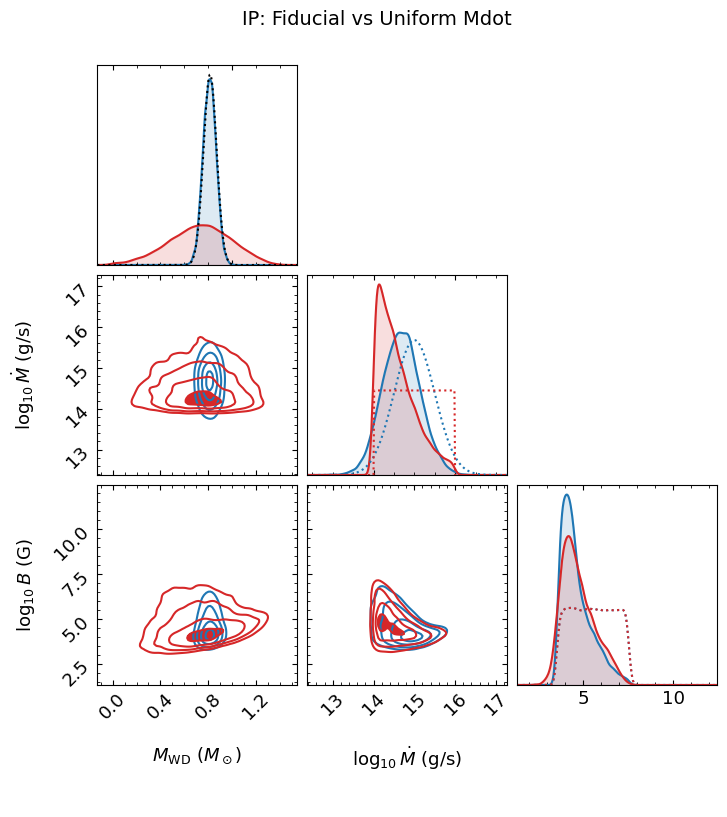

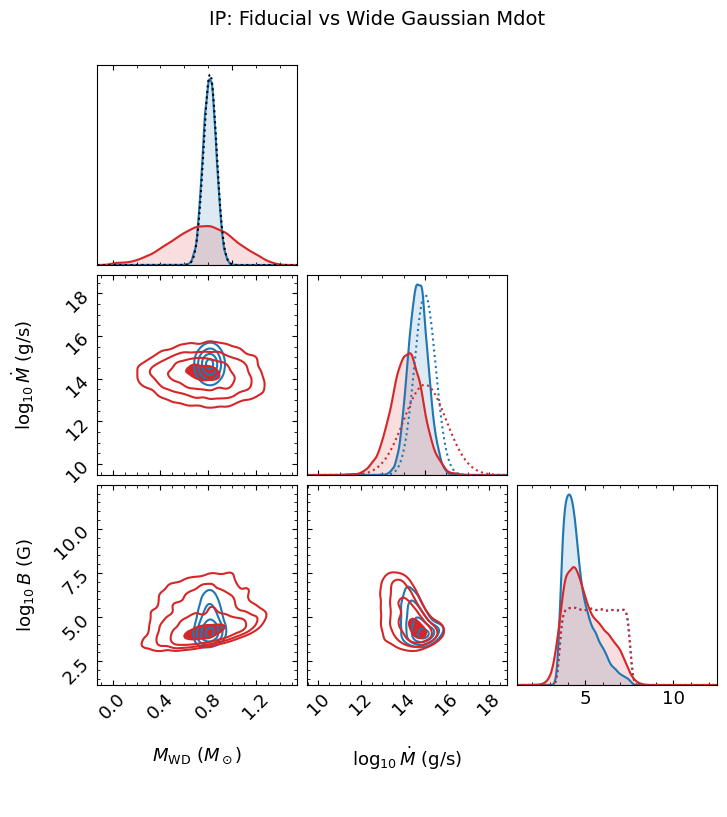

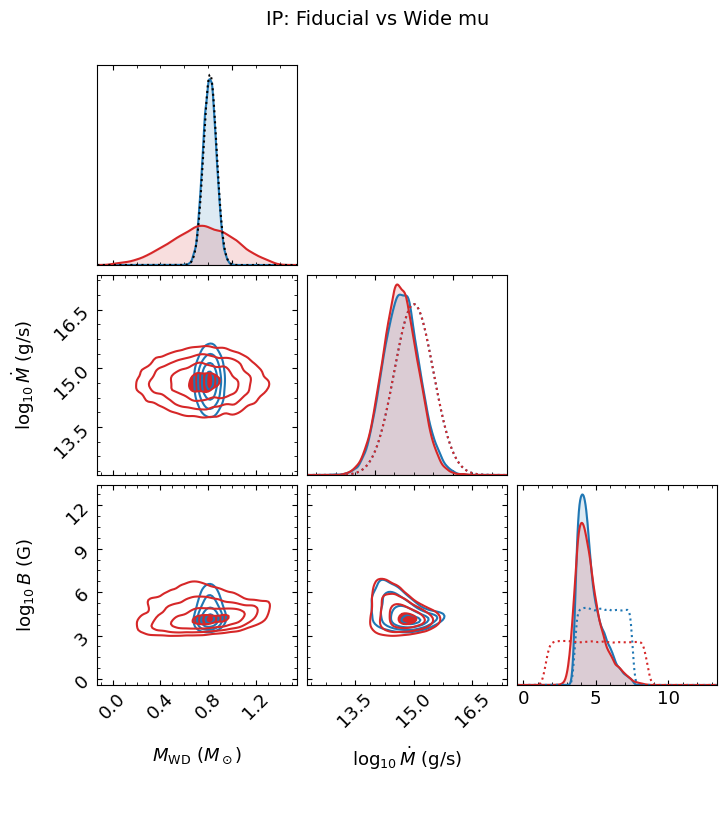

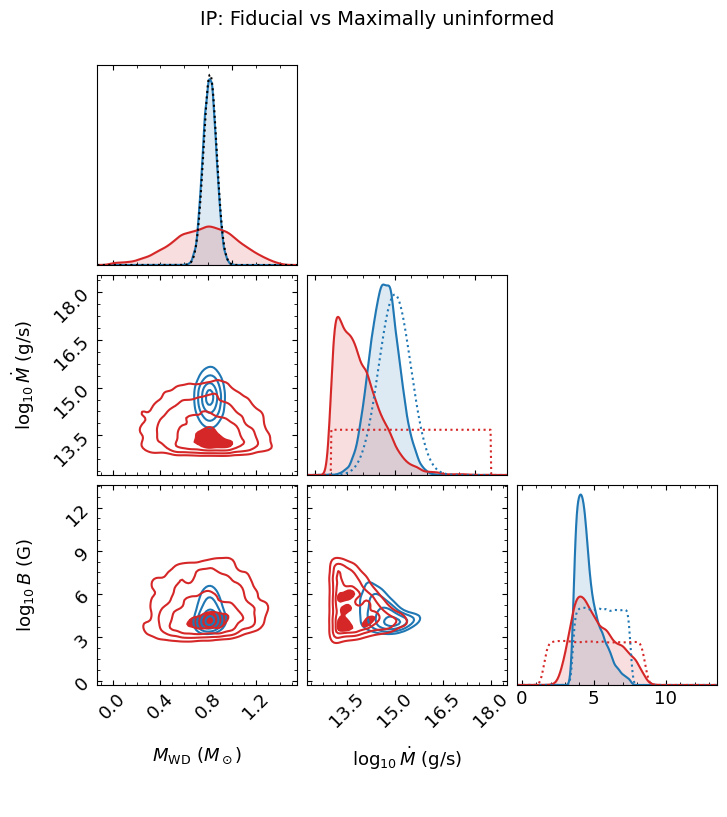

In [56]:
# --- Corner plots: fiducial (blue) vs each alternative (red) ---
import copy
from scipy.stats import gaussian_kde
from matplotlib.lines import Line2D

def results_to_logB(res):
    """Convert log10(mu) -> log10(B) in a copy of dynesty results."""
    res_B = copy.deepcopy(res)
    R_arr = np.array([get_R(m) for m in res_B['samples'][:, 0]])
    B_arr = 10**res_B['samples'][:, 2] / R_arr**3
    res_B['samples'][:, 2] = np.log10(B_arr)
    return res_B


def get_eq_samples(res):
    """Extract equal-weight posterior samples from dynesty results."""
    w = np.exp(res['logwt'] - res['logz'][-1])
    w /= w.sum()
    return dyfunc.resample_equal(res['samples'], w)


def prior_pdf_mdot(grid, mdot_type, mdot_params):
    """Prior PDF for log10(Mdot), density-normalized."""
    if mdot_type == 'gaussian':
        return norm.pdf(grid, loc=mdot_params[0], scale=mdot_params[1])
    else:
        lo, hi = mdot_params
        return np.where((grid >= lo) & (grid <= hi), 1.0 / (hi - lo), 0.0)


def prior_pdf_logB(grid, logmu_lo, logmu_hi, n=100000):
    """Prior PDF for log10(B), derived from uniform log10(mu) + mass prior."""
    rng = np.random.default_rng(42)
    M_prior = rng.normal(IP_M_MU, IP_M_SIG, n)
    M_prior = np.clip(M_prior, M_min_table + 0.001, M_max_table - 0.001)
    logmu_prior = rng.uniform(logmu_lo, logmu_hi, n)
    R_prior = np.array([get_R(m) for m in M_prior])
    logB_prior = logmu_prior - 3 * np.log10(R_prior)
    return gaussian_kde(logB_prior)(grid)


def redraw_diagonals(axes, eq_samples_list, colors, prior_pdfs, prior_colors, span):
    """Clear diagonal axes and redraw posteriors + priors in density normalization.

    eq_samples_list: list of (N, ndim) equal-weight sample arrays
    colors: list of colors for each posterior
    prior_pdfs: list-of-lists, prior_pdfs[i] = [(pdf_values, color), ...] for param i
    span: list of (lo, hi) per parameter
    """
    ndim = len(span)
    for i in range(ndim):
        ax = axes[i, i]
        # Preserve axis labels/ticks, clear only plot content
        xlim = ax.get_xlim()
        xlabel = ax.get_xlabel()
        ax.clear()

        grid = np.linspace(*span[i], 300)

        # Plot posterior KDEs (density-normalized, area = 1)
        for samples, color in zip(eq_samples_list, colors):
            kde = gaussian_kde(samples[:, i])
            pdf = kde(grid)
            ax.plot(grid, pdf, color=color, lw=1.5)
            ax.fill_between(grid, pdf, alpha=0.15, color=color)

        # Plot priors (dotted, already density-normalized)
        for pdf_vals, pcolor in prior_pdfs[i]:
            ax.plot(grid, pdf_vals, color=pcolor, ls=":", lw=1.5)

        ax.set_xlim(*span[i])
        ax.set_ylim(bottom=0)
        ax.set_yticks([])
        if i < ndim - 1:
            ax.set_xticklabels([])
            ax.set_xlabel('')
        else:
            ax.set_xlabel(xlabel)


# Fiducial prior specs
fid_mdot = ("gaussian", (LOGMDOT_MU, LOGMDOT_SIG))
fid_logmu = (LOGMU_LO, LOGMU_HI)

fiducial_ip_B = results_to_logB(results_ip)
fid_eq = get_eq_samples(fiducial_ip_B)

labels_ip = [r'$M_{\rm WD}$ ($M_\odot$)',
             r'$\log_{10}\dot{M}$ (g/s)',
             r'$\log_{10} B$ (G)']

plt.rcParams['figure.constrained_layout.use'] = False

for cfg in prior_configs:
    label = cfg['label']
    r = sensitivity_results[label]
    alt_ip_B = results_to_logB(r['results_ip'])
    alt_eq = get_eq_samples(alt_ip_B)

    # Compute spans that encompass both posteriors
    all_samples = np.vstack([fiducial_ip_B['samples'], alt_ip_B['samples']])
    span = [(col.min() - 0.1*(col.max()-col.min()),
             col.max() + 0.1*(col.max()-col.min()))
            for col in all_samples.T]

    # Use dyplot for 2D off-diagonal panels
    fig, axes = dyplot.cornerplot(
        fiducial_ip_B, span=span, labels=labels_ip,
        quantiles=None, show_titles=True,
        title_quantiles=[0.16, 0.5, 0.84],
        title_fmt='.3f',
        title_kwargs={'fontsize': 12},
        label_kwargs={'fontsize': 13}, color='C0')

    dyplot.cornerplot(
        alt_ip_B, span=span, labels=labels_ip,
        quantiles=None, show_titles=True,
        title_quantiles=[0.16, 0.5, 0.84],
        title_fmt='.3f',
        title_kwargs={'fontsize': 12},
        label_kwargs={'fontsize': 13}, color='C3',
        fig=(fig, axes))

    # Build prior PDFs for each parameter
    grids = [np.linspace(*s, 300) for s in span]

    # M_WD: same Gaussian prior for both (black dotted)
    mwd_prior = norm.pdf(grids[0], IP_M_MU, IP_M_SIG)
    prior_pdfs_per_param = [
        [(mwd_prior, 'k')],  # M_WD: single prior
        [(prior_pdf_mdot(grids[1], *fid_mdot), 'C0'),  # Mdot: fiducial vs alt
         (prior_pdf_mdot(grids[1], cfg['mdot_type'], cfg['mdot_params']), 'C3')],
        [(prior_pdf_logB(grids[2], *fid_logmu), 'C0'),  # B: fiducial vs alt
         (prior_pdf_logB(grids[2], cfg['logmu_lo'], cfg['logmu_hi']), 'C3')],
    ]

    # Redraw diagonals with consistent density normalization
    redraw_diagonals(axes, [fid_eq, alt_eq], ['C0', 'C3'],
                     prior_pdfs_per_param, None, span)

    # Legend
    handles = [Line2D([0], [0], color='C0', lw=2, label='Fiducial'),
               Line2D([0], [0], color='C3', lw=2, label=label),
               Line2D([0], [0], color='k', ls=':', lw=1.5, label='Prior (shared)'),
               Line2D([0], [0], color='C0', ls=':', lw=1.5, label='Fiducial prior'),
               Line2D([0], [0], color='C3', ls=':', lw=1.5, label=f'{label} prior')]
    #fig.legend(handles=handles, loc='upper right', fontsize=11)

    fig.suptitle(f'IP: Fiducial vs {label}', fontsize=14, y=1.02)
    safe_label = label.lower().replace(' ', '_')
    fig.savefig(f'{savedir}/bayesian_sensitivity_{safe_label}.pdf', bbox_inches='tight')
    plt.show()

plt.rcParams['figure.constrained_layout.use'] = True

**Interpretation**: The table above shows the Bayes factor under each prior configuration. If ln(BF) remains consistent across all variants, the model comparison is robust to reasonable prior choices. Significant shifts would indicate that the evidence is prior-dominated and should be interpreted with caution.